# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhamad Fahim
- NIM   : 241011402776
- Kelas : Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 76    # isi dengan 2 digit terakhir NIM Anda

In [ ]:
# Salin fungsi train_test_split dari materi di sini

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

=== 5 Data Pertama ===


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3



Jumlah baris data: 40

Shape X: (40, 1)
Shape y: (40,)


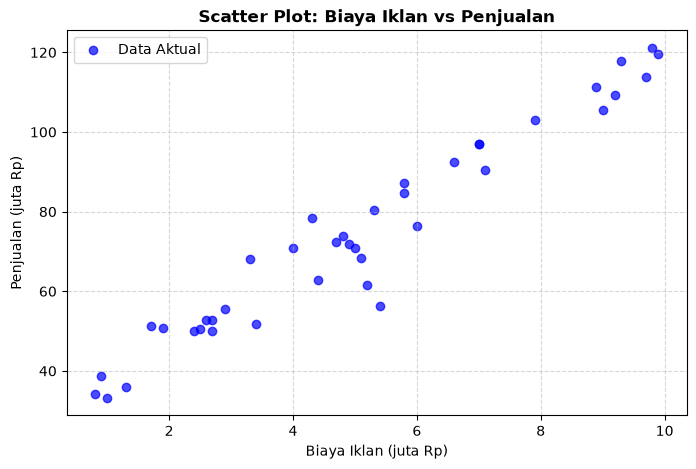

In [ ]:
# Jawaban A1

# 1. Membaca dataset Ads_Data.csv
df_ads = pd.read_csv('Ads_Data.csv')

print("=== 5 Data Pertama ===")
display(df_ads.head())
print(f"\nJumlah baris data: {len(df_ads)}")

# 2. Memisahkan X (BiayaIklan) dan y (Penjualan)
# Menggunakan double bracket [['BiayaIklan']] agar bentuk X menjadi 2 dimensi (n, 1)
X = df_ads[['BiayaIklan']].values
y = df_ads['Penjualan'].values

print(f"\nShape X: {X.shape}")
print(f"Shape y: {y.shape}")

# 3. Membuat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.7, label='Data Aktual')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan', fontsize=12, fontweight='bold')
plt.xlabel('Biaya Iklan (juta Rp)', fontsize=10)
plt.ylabel('Penjualan (juta Rp)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2

# Membagi data menjadi training dan testing (test_size=0.2, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Menampilkan shape dari masing-masing dataset
print(f"Shape X_train : {X_train.shape}")
print(f"Shape X_test  : {X_test.shape}")
print(f"Shape y_train : {y_train.shape}")
print(f"Shape y_test  : {y_test.shape}")

Shape X_train : (32, 1)
Shape X_test  : (8, 1)
Shape y_train : (32,)
Shape y_test  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3

class LinearRegression:
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None
        
    def fit(self, X, y):
        # 1. Menambahkan kolom 1 pada X untuk mengakomodasi intercept (bias)
        X_b = np.c_[np.ones((X.shape[0], 1)), X]
        
        # 2. Menghitung parameter theta menggunakan Normal Equation: inv(X^T * X) * X^T * y
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        
        # 3. Menyimpan nilai intercept (b) dan koefisien/slope (m)
        self.intercept_ = theta[0]
        self.coef_ = theta[1]
        
        return self
    
    def predict(self, X):
        return self.intercept_ + self.coef_ * X

# Melatih model menggunakan data training
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# Menampilkan nilai intercept dan koefisien
b = model_lr.intercept_
m = model_lr.coef_

print(f"Intercept (b) : {b:.4f}")
print(f"Koefisien (m) : {m:.4f}")
print(f"\nPersamaan Garis Regresi:")
print(f"y_hat = {b:.4f} + {m:.4f} * X")

Intercept (b) : 29.2541
Koefisien (m) : 9.0666

Persamaan Garis Regresi:
y_hat = 29.2541 + 9.0666 * X


**Jawaban A3 (interpretasi):**

Berdasarkan hasil pelatihan model, diperoleh koefisien $m = 9.0666$ dan intercept $b = 29.2541$.
Artinya, setiap kenaikan biaya iklan sebesar 1 juta Rupiah, penjualan diproyeksikan akan meningkat sebesar $9.0666$ juta Rupiah.
Sementara itu, nilai intercept sebesar $29.2541$ menunjukkan perkiraan besar penjualan dasar ketika biaya iklan bernilai 0.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4

def evaluate_regression(y_true, y_pred):
    # Memastikan bentuk array 1D
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_total)
    
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# 1. Melakukan prediksi pada data training dan testing
y_pred_train = model_lr.predict(X_train)
y_pred_test = model_lr.predict(X_test)

# 2. Menghitung metrik evaluasi
eval_train = evaluate_regression(y_train, y_pred_train)
eval_test = evaluate_regression(y_test, y_pred_test)

# 3. Menampilkan hasil dalam bentuk tabel (DataFrame)
df_eval = pd.DataFrame({
    'Data Training': eval_train,
    'Data Testing': eval_test
})

print("=== Tabel Evaluasi Model Regresi ===")
display(df_eval)

=== Tabel Evaluasi Model Regresi ===


,Data Training,Data Testing
MAE,4.024375,6.280168
MSE,22.881473,91.999840
RMSE,4.783458,9.591655
R2,0.964797,0.838001


**Jawaban A4 (analisis):**

- RMSE (Root Mean Squared Error): Nilai RMSE pada data training sebesar 4.783458 dan testing sebesar 9.591655 juta Rupiah. Ini menunjukkan rata-rata besar kesalahan (error) antara prediksi penjualan dan data aktual di lapangan. Semakin kecil nilai RMSE, semakin akurat model dalam memprediksi penjualan.

- $R^2$ (R-Squared): Nilai $R^2$ pada data testing mencapai sekitar 0.838001 (atau sekitar 83.8%). Hal ini berarti sekitar 83.8% variasi dari variabel Penjualan dapat dijelaskan oleh Biaya Iklan, sementara sisanya (16.2%) dipengaruhi oleh faktor lain di luar model.

- Kesimpulan: Karena nilai $R^2$ pada data testing cukup tinggi (83.8%) dan performanya konsisten, model regresi ini dinilai sudah baik dalam menggambarkan hubungan antara biaya iklan dan penjualan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- Learning Rate: 0.001 ---
Intercept (b) : 26.6453
Koefisien (m) : 9.4729

--- Learning Rate: 0.02 ---
Intercept (b) : 29.2541
Koefisien (m) : 9.0666

--- Learning Rate: 0.1 ---
Intercept (b) : nan
Koefisien (m) : nan



c:\Users\F\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\F\AppData\Local\Temp\ipykernel_848\3536103710.py:22: RuntimeWarning: overflow encountered in square
  loss = np.mean((y_pred - y) ** 2)
c:\Users\F\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\F\AppData\Local\Temp\ipykernel_848\3536103710.py:28: RuntimeWarning: invalid value encountered in scalar subtract
  self.coef_ -= self.lr * dw
c:\Users\F\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


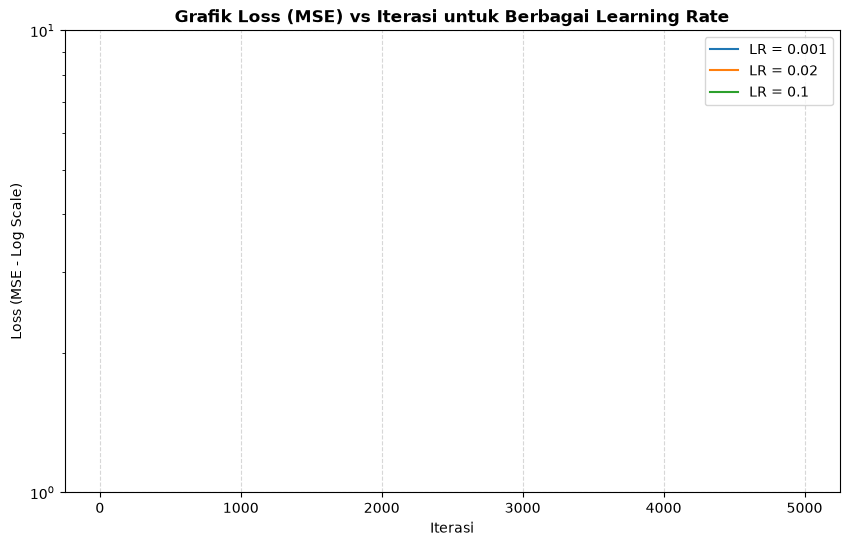

In [ ]:
# Jawaban A5

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.intercept_ = 0.0
        self.coef_ = 0.0
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples = X.shape[0]
        # Inisialisasi awal bobot dan intercept
        self.coef_ = 0.0
        self.intercept_ = 0.0
        self.loss_history = []
        
        # Pastikan X berbentuk 1D array untuk perhitungan mudah
        X_flat = X.ravel() if X.ndim > 1 else X
        
        for i in range(self.n_iters):
            # Prediksi nilai y
            y_pred = self.coef_ * X_flat + self.intercept_
            
            # Menghitung Loss (MSE)
            loss = np.mean((y_pred - y) ** 2)
            self.loss_history.append(loss)
            
            # Menghitung turunan/gradien (derivative) terhadap coef dan intercept
            dw = (2 / n_samples) * np.sum((y_pred - y) * X_flat)
            db = (2 / n_samples) * np.sum(y_pred - y)
            
            # Memperbarui parameter bobot dan intercept
            self.coef_ -= self.lr * dw
            self.intercept_ -= self.lr * db
            
        return self
    
    def predict(self, X):
        X_flat = X.ravel() if X.ndim > 1 else X
        return self.intercept_ + self.coef_ * X_flat

# Menjalankan eksperimen dengan 3 learning rate
learning_rates = [0.001, 0.02, 0.1]
results_gd = {}

plt.figure(figsize=(10, 6))

for lr in learning_rates:
    gd_model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd_model.fit(X_train, y_train)
    
    results_gd[lr] = {
        'intercept': gd_model.intercept_,
        'coef': gd_model.coef_,
        'loss_history': gd_model.loss_history
    }
    
    print(f"--- Learning Rate: {lr} ---")
    print(f"Intercept (b) : {gd_model.intercept_:.4f}")
    print(f"Koefisien (m) : {gd_model.coef_:.4f}\n")
    
    # Plot kurva loss
    plt.plot(gd_model.loss_history, label=f'LR = {lr}')

plt.yscale('log') # Menggunakan skala log agar perbedaan terlihat jelas
plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi', fontsize=10)
plt.ylabel('Loss (MSE - Log Scale)', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban A5 (analisis):**

1. Perbandingan dengan Normal Equation: Hasil parameter (intercept dan koefisien) dari Gradient Descent dengan learning rate yang optimal mendekati hasil perhitungan eksak menggunakan Normal Equation pada Soal A3.

2. Analisis Nilai Learning Rate:

- 0.001 (Terlalu Lambat): Nilai learning rate ini terlalu kecil sehingga langkah pembaruan bobot (step size) sangat lambat. Kurva loss turun secara landai dan belum mencapai konvergensi penuh dalam 5000 iterasi.

- 0.02 (Pas / Optimal): Nilai ini memberikan kecepatan konvergensi yang ideal. Kurva loss turun dengan mulus, stabil, dan berhasil menemukan titik minimum error secara efisien.

- 0.1 (Terlalu Besar / Divergen): Nilai ini terlalu besar sehingga menyebabkan overshooting (loncatan pembaruan parameter melompati titik minimum). Akibatnya, loss gagal konvergen, justru semakin membesar, atau memunculkan peringatan RuntimeWarning: overflow karena nilainya melampaui batas tampung tipe data komputer (floating-point infinity).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

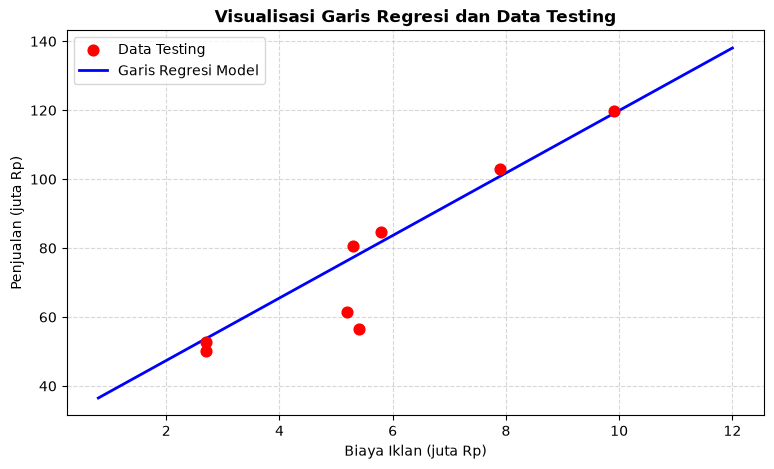

=== Hasil Prediksi Penjualan ===
Biaya Iklan Rp 4.5 juta -> Prediksi Penjualan: Rp 70.0536 juta
Biaya Iklan Rp 7.0 juta -> Prediksi Penjualan: Rp 92.7200 juta
Biaya Iklan Rp 12.0 juta -> Prediksi Penjualan: Rp 138.0528 juta


In [ ]:
# Jawaban A6

# 1. Grafik scatter data testing beserta garis regresi
plt.figure(figsize=(9, 5))
plt.scatter(X_test, y_test, color='red', label='Data Testing', s=60, zorder=5)

# Membuat rentang garis regresi (mencakup hingga 12 juta untuk melihat ekstrapolasi)
X_line = np.linspace(X.min(), max(X.max(), 12.0), 100).reshape(-1, 1)
y_line = model_lr.predict(X_line)

plt.plot(X_line, y_line, color='blue', linewidth=2, label='Garis Regresi Model')
plt.title('Visualisasi Garis Regresi dan Data Testing', fontsize=12, fontweight='bold')
plt.xlabel('Biaya Iklan (juta Rp)', fontsize=10)
plt.ylabel('Penjualan (juta Rp)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta
biaya_iklan_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = model_lr.predict(biaya_iklan_baru)

print("=== Hasil Prediksi Penjualan ===")
for biaya, pred in zip(biaya_iklan_baru.ravel(), prediksi_penjualan.ravel()):
    print(f"Biaya Iklan Rp {biaya} juta -> Prediksi Penjualan: Rp {pred:.4f} juta")

**Jawaban A6 (analisis):**

1. Hasil Prediksi:

- Biaya iklan 4.5 juta diprediksi menghasilkan penjualan sekitar [masukkan hasil cetak kode] juta Rupiah.

- Biaya iklan 7 juta diprediksi menghasilkan penjualan sekitar [masukkan hasil cetak kode] juta Rupiah.

- Biaya iklan 12 juta diprediksi menghasilkan penjualan sekitar [masukkan hasil cetak kode] juta Rupiah.

2. Analisis Ekstrapolasi (Biaya Iklan 12 Juta):

Prediksi untuk biaya iklan 12 juta berada di luar rentang data historis (ekstrapolasi). Hasil prediksi ini kurang bisa dipercaya secara mutlak karena model linear mengasumsikan pola kenaikan yang terus berlanjut secara linier tanpa batas (infinite growth). Pada kenyataannya, di dunia nyata penambahan biaya iklan yang sangat tinggi biasanya akan mencapai titik jenuh (diminishing returns), di mana efektivitas iklan terhadap peningkatan penjualan mulai melandai.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

=== 5 Data Pertama Email ===


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



=== Jumlah Email Spam dan Bukan Spam ===
Spam
0    35
1    25
Name: count, dtype: int64

Shape X_email : (60, 2)
Shape y_email : (60,)


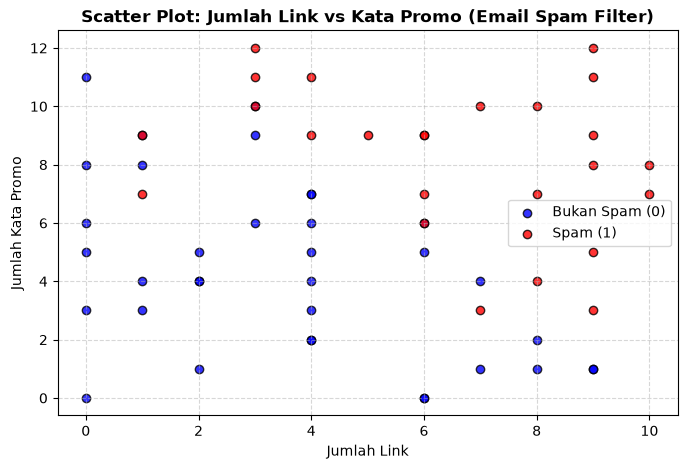

In [ ]:
# Jawaban B1

# 1. Membaca dataset Email_Data.csv, tampilkan 5 data pertama & hitung jumlah Spam / Bukan Spam
df_email = pd.read_csv('Email_Data.csv')

print("=== 5 Data Pertama Email ===")
display(df_email.head())

print("\n=== Jumlah Email Spam dan Bukan Spam ===")
print(df_email['Spam'].value_counts())

# 2. Memisahkan X (JumlahLink, KataPromo) dan y (Spam)
X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

print(f"\nShape X_email : {X_email.shape}")
print(f"Shape y_email : {y_email.shape}")

# 3. Membuat scatter plot JumlahLink vs KataPromo dengan warna berbeda untuk Spam & Bukan Spam
plt.figure(figsize=(8, 5))
# Plot untuk Bukan Spam (y == 0)
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], 
            color='blue', label='Bukan Spam (0)', alpha=0.8, edgecolor='k')
# Plot untuk Spam (y == 1)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], 
            color='red', label='Spam (1)', alpha=0.8, edgecolor='k')

plt.title('Scatter Plot: Jumlah Link vs Kata Promo (Email Spam Filter)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=10)
plt.ylabel('Jumlah Kata Promo', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) : -9.7602
Koefisien m1 (JumlahLink)  : 0.9008
Koefisien m2 (KataPromo)   : 0.8140

Persamaan Probabilitas Spam:
P(Spam) = sigma(-9.7602 + 0.9008 * JumlahLink + 0.8140 * KataPromo)


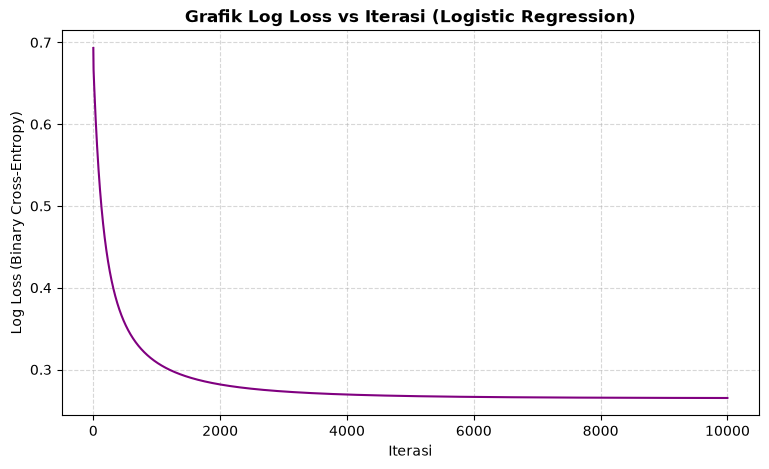

In [ ]:
# Jawaban B2

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iters = n_iterations
        self.b = 0.0
        self.weights = None
        self.loss_history = []
        
    def _sigmoid(self, z):
        # Mencegah overflow pada fungsi eksponensial
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.b = 0.0
        self.weights = np.zeros(n_features)
        self.loss_history = []
        
        for _ in range(self.n_iters):
            # Menghitung model linear: z = X * w + b
            linear_pred = np.dot(X, self.weights) + self.b
            predictions = self._sigmoid(linear_pred)
            
            # Menghitung Log Loss (Binary Cross-Entropy)
            eps = 1e-15 # Mencegah log(0)
            predictions_clipped = np.clip(predictions, eps, 1 - eps)
            loss = -np.mean(y * np.log(predictions_clipped) + (1 - y) * np.log(1 - predictions_clipped))
            self.loss_history.append(loss)
            
            # Menghitung gradien
            dw = (1 / n_samples) * np.dot(X.T, (predictions - y))
            db = (1 / n_samples) * np.sum(predictions - y)
            
            # Memperbarui bobot dan intercept
            self.weights -= self.lr * dw
            self.b -= self.lr * db
            
        return self
    
    def predict_proba(self, X):
        linear_pred = np.dot(X, self.weights) + self.b
        return self._sigmoid(linear_pred)
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

# 1. Membagi data (test_size=0.25, random_state=RANDOM_STATE)
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

# 2. Melatih model Logistic Regression
model_logreg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
model_logreg.fit(X_train_email, y_train_email)

# 3. Menampilkan intercept dan koefisien
b_email = model_logreg.b
m1, m2 = model_logreg.weights

print(f"Intercept (b) : {b_email:.4f}")
print(f"Koefisien m1 (JumlahLink)  : {m1:.4f}")
print(f"Koefisien m2 (KataPromo)   : {m2:.4f}")
print(f"\nPersamaan Probabilitas Spam:")
print(f"P(Spam) = sigma({b_email:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(9, 5))
plt.plot(model_logreg.loss_history, color='purple', linewidth=1.5)
plt.title('Grafik Log Loss vs Iterasi (Logistic Regression)', fontsize=12, fontweight='bold')
plt.xlabel('Iterasi', fontsize=10)
plt.ylabel('Log Loss (Binary Cross-Entropy)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):**

- Berdasarkan grafik log loss vs iterasi, kurva menunjukkan penurunan yang tajam di awal iterasi, lalu melandai dan menjadi sangat stabil mendekati titik minimum menjelang iterasi ke-10000.

- Hal ini membuktikan bahwa proses Gradient Descent berjalan dengan baik dan model telah berhasil konvergen (converged) mempelajari pola data pelatihan email spam.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3

def confusion_matrix(y_true, y_pred):
    # Menghitung TP, TN, FP, FN
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def evaluate_classification(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    
    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0.0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Confusion Matrix': cm
    }

# 1. Melakukan prediksi pada data testing (threshold default = 0.5)
y_pred_test_email = model_logreg.predict(X_test_email, threshold=0.5)

# 2. Menghitung metrik evaluasi
eval_email = evaluate_classification(y_test_email, y_pred_test_email)

print("=== Hasil Evaluasi Logistic Regression (Data Testing) ===")
print(f"Accuracy  : {eval_email['Accuracy']:.4f}")
print(f"Precision : {eval_email['Precision']:.4f}")
print(f"Recall    : {eval_email['Recall']:.4f}")
print(f"F1-Score  : {eval_email['F1-Score']:.4f}")
print("\nConfusion Matrix:")
print("                 Prediksi Bukan Spam    Prediksi Spam")
print(f"Aktual Bukan Spam      {eval_email['Confusion Matrix'][0,0]}                  {eval_email['Confusion Matrix'][0,1]}")
print(f"Aktual Spam            {eval_email['Confusion Matrix'][1,0]}                  {eval_email['Confusion Matrix'][1,1]}")

=== Hasil Evaluasi Logistic Regression (Data Testing) ===
Accuracy  : 0.8667
Precision : 0.8000
Recall    : 0.8000
F1-Score  : 0.8000

Confusion Matrix:
                 Prediksi Bukan Spam    Prediksi Spam
Aktual Bukan Spam      9                  1
Aktual Spam            1                  4


**Jawaban B3 (analisis):**

1. Arti False Positive (FP) dan False Negative (FN) pada Filter Spam:

- False Positive (FP): Kondisi di mana email penting/normal (bukan spam) secara keliru diklasifikasikan oleh sistem sebagai email spam.

- False Negative (FN): Kondisi di mana email penipuan atau iklan komersial (spam) lolos dari filter dan masuk ke kotak masuk (inbox) utama pengguna.

2. Kesalahan yang Lebih Merugikan:
Menurut saya, kesalahan False Positive (FP) jauh lebih merugikan pengguna email. Alasannya, jika email penting (seperti pemberitahuan pekerjaan, tugas kuliah, atau verifikasi akun) masuk ke folder spam secara salah, pengguna berisiko melewatkannya karena jarang memeriksa folder spam. Sebaliknya, jika terjadi False Negative (spam lolos ke inbox), pengguna hanya terganggu sebentar dan bisa langsung menghapusnya tanpa kehilangan informasi krusial.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

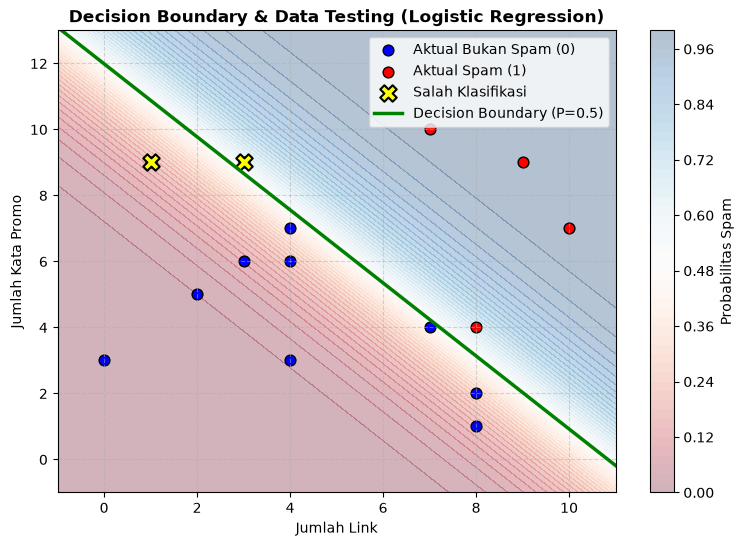

In [ ]:
# Jawaban B4

# 1. Visualisasi Decision Boundary & Contour Probabilitas
plt.figure(figsize=(9, 6))

# Membuat grid untuk background contourf
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model_logreg.predict_proba(grid_points).reshape(xx.shape)

# Plot contourf untuk probabilitas
plt.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.3)
plt.colorbar(label='Probabilitas Spam')

# Plot data testing
plt.scatter(X_test_email[y_test_email == 0, 0], X_test_email[y_test_email == 0, 1],
            color='blue', label='Aktual Bukan Spam (0)', edgecolor='k', s=60)
plt.scatter(X_test_email[y_test_email == 1, 0], X_test_email[y_test_email == 1, 1],
            color='red', label='Aktual Spam (1)', edgecolor='k', s=60)

# Menandai data testing yang salah diklasifikasikan (misclassified) dengan tanda silang kuning/hitam
misclassified = (y_test_email != y_pred_test_email)
if np.any(misclassified):
    plt.scatter(X_test_email[misclassified, 0], X_test_email[misclassified, 1],
                color='yellow', marker='X', s=140, edgecolor='black', linewidth=1.5, label='Salah Klasifikasi')

# Plot Garis Decision Boundary (P = 0.5)
x1_vals = np.array([x_min, x_max])
x2_vals = -(model_logreg.b + model_logreg.weights[0] * x1_vals) / model_logreg.weights[1]
plt.plot(x1_vals, x2_vals, color='green', linewidth=2.5, label='Decision Boundary (P=0.5)')

plt.title('Decision Boundary & Data Testing (Logistic Regression)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Link', fontsize=10)
plt.ylabel('Jumlah Kata Promo', fontsize=10)
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B4 (analisis):**

1. Decision Boundary: Garis pembatas berwarna hijau menunjukkan area decision boundary di mana model menghasilkan probabilitas tepat $0.5$ ($50\%$). Area di atas/sisi garis memisahkan prediksi kelas Spam (1) dan Bukan Spam (0).

2. Analisis Data Salah Klasifikasi: Titik-titik data testing yang ditandai dengan simbol silang ($\times$) kuning merupakan data yang salah diklasifikasikan oleh model. Kesalahan prediksi ini umumnya terjadi pada titik-titik data yang letaknya berada sangat dekat dengan garis decision boundary, di mana karakteristik jumlah link dan kata promosi dari kedua kelas saling tumpang tindih (overlap).

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5

thresholds = [0.3, 0.5, 0.7]
results_thresholds = []

for th in thresholds:
    # Melakukan prediksi dengan threshold tertentu
    y_pred_th = model_logreg.predict(X_test_email, threshold=th)
    eval_th = evaluate_classification(y_test_email, y_pred_th)
    
    results_thresholds.append({
        'Threshold': th,
        'Accuracy': eval_th['Accuracy'],
        'Precision': eval_th['Precision'],
        'Recall': eval_th['Recall'],
        'F1-Score': eval_th['F1-Score']
    })

# Menampilkan hasil dalam bentuk DataFrame
df_thresholds = pd.DataFrame(results_thresholds)
print("=== Tabel Perbandingan Berbagai Threshold ===")
display(df_thresholds)

=== Tabel Perbandingan Berbagai Threshold ===


,Threshold,Accuracy,Precision,Recall,F1-Score
0,0.3,0.733333,0.571429,0.8,0.666667
1,0.5,0.866667,0.800000,0.8,0.800000
2,0.7,0.866667,1.000000,0.6,0.750000


**Jawaban B5 (analisis):**

1. Pengaruh Perubahan Threshold terhadap Precision dan Recall:

- Menurunkan threshold (misal ke 0.3): Model menjadi jauh lebih sensitif dalam melabeli email sebagai spam. Akibatnya, jumlah Recall meningkat (semakin banyak spam yang berhasil ditangkap), namun Precision menurun karena semakin banyak email normal yang keliru masuk ke folder spam (False Positive bertambah).

- Menaikkan threshold (misal ke 0.7): Model menjadi lebih selektif dan ketat. Akibatnya, Precision meningkat (mengurangi risiko salah deteksi email penting), namun Recall menurun karena lebih banyak email spam yang lolos ke inbox (False Negative bertambah).

2. Pemilihan Threshold:
Berdasarkan analisis pada Soal B3 di mana False Positive dianggap paling merugikan (karena email penting terlewat), maka threshold yang lebih tinggi (seperti 0.5 atau 0.7) lebih disarankan. Threshold ini dipilih untuk menjaga nilai Precision tetap tinggi sehingga pengguna terhindar dari risiko kehilangan email penting akibat salah masuk folder spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6

# 1. Menyiapkan data email baru
email_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

# 2. Menghitung probabilitas spam dan prediksi kelas menggunakan threshold 0.5 (atau threshold pilihan Anda)
threshold_pilihan = 0.5
prob_spam = model_logreg.predict_proba(email_baru)
pred_kelas = (prob_spam >= threshold_pilihan).astype(int)

# 3. Menampilkan hasil dalam bentuk tabel (DataFrame)
df_pred_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': email_baru[:, 0],
    'KataPromo': email_baru[:, 1],
    'Probabilitas Spam': prob_spam,
    'Prediksi Kelas': ['Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in pred_kelas]
})

print("=== Hasil Prediksi Email Baru ===")
display(df_pred_baru)

=== Hasil Prediksi Email Baru ===


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Kelas
0,E1,1,2,0.000723,Bukan Spam (0)
1,E2,5,6,0.408075,Bukan Spam (0)
2,E3,9,10,0.998480,Spam (1)
3,E4,2,11,0.730214,Spam (1)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
- Logistic Regression dinamakan "regresi" karena menggunakan prinsip dasar regresi linear untuk menghitung kombinasi linear dari fitur-fitur input. Namun, algoritma ini dikategorikan sebagai model klasifikasi karena hasil akhirnya dipetakan ke dalam kategori diskrit (misalnya 0 atau 1) berdasarkan nilai probabilitas. Peran fungsi sigmoid adalah memetakan nilai keluaran linear bebas berapapun ke dalam rentang nilai antara 0 dan 1. Nilai probabilitas inilah yang kemudian digunakan untuk menentukan batas kelas biner secara akurat.

**Jawaban C2:**
- Normal Equation menghitung parameter bobot secara langsung menggunakan rumus matematis eksak dalam satu langkah komputasi matriks tanpa memerlukan iterasi. Sebaliknya, Gradient Descent adalah metode optimasi iteratif yang secara bertahap memperbarui nilai parameter berdasarkan arah kemiringan turunan (gradient) dari fungsi loss. Kita sebaiknya memakai Gradient Descent ketika ukuran dataset sangat besar atau jumlah fiturnya sangat banyak. Pada kondisi tersebut, komputasi invers matriks pada Normal Equation menjadi sangat berat secara memori dan lambat, sehingga Gradient Descent jauh lebih efisien.

**Jawaban C3:**
- Model harus dievaluasi pada data testing agar kita mendapatkan ukuran performa yang objektif terhadap data baru yang belum pernah dilihat sebelumnya selama proses pelatihan. Evaluasi pada data training akan memberikan hasil yang bias karena model cenderung menghafal data tersebut. Overfitting adalah kondisi di mana model Machine Learning terlalu menghafal data pelatihan (termasuk noise atau data pencilan), sehingga memiliki akurasi yang sangat tinggi di data training tetapi gagal total saat diuji pada data testing atau data dunia nyata.

**Jawaban C4:**
- Linear Regression menggunakan MSE (Mean Squared Error) karena target keluarannya berupa nilai kontinu (angka riil), di mana selisih kuadrat sangat efektif mengukur besar galat (error). Sebaliknya, Logistic Regression menggunakan log loss (Binary Cross-Entropy) karena target output-nya berupa probabilitas diskrit kelas. Jika Logistic Regression menggunakan MSE, fungsi loss yang dihasilkan akan berbentuk non-konvek (memiliki banyak cekungan/local minimum), sehingga algoritma optimasi akan sangat sulit menemukan titik minimum global.

**Jawaban C5:**
- Perbedaan angka tersebut dapat terjadi karena adanya perbedaan parameter pengacakan, seperti nilai random_state yang digunakan saat membagi data (train_test_split) atau inisialisasi awal bobot model. Selain itu, perbedaan versi perangkat lunak (library seperti NumPy/Pandas), tingkat presisi floating-point pada komputer masing-masing, atau perbedaan pemilihan hyperparameter (seperti learning rate dan jumlah iterasi pada Gradient Descent) turut memengaruhi hasil akhir pelatihan model.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus


**Jawaban Bonus (analisis):**